In [4]:
import io
import json
import os
import sys
from mpmath import mp
from contextlib import redirect_stdout

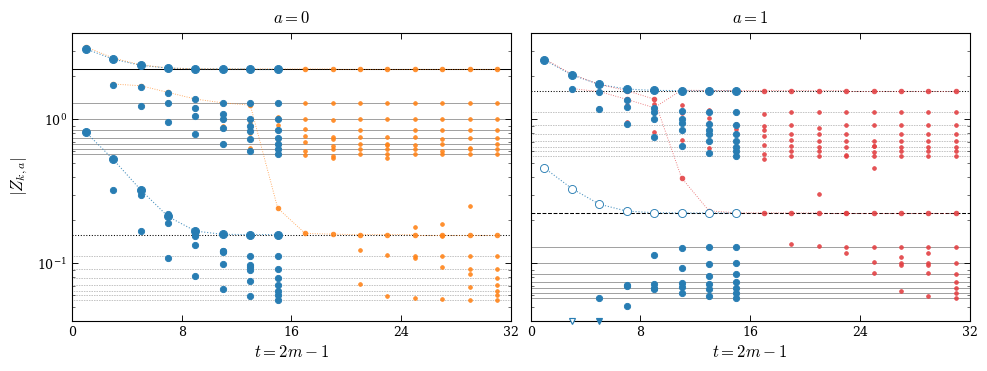

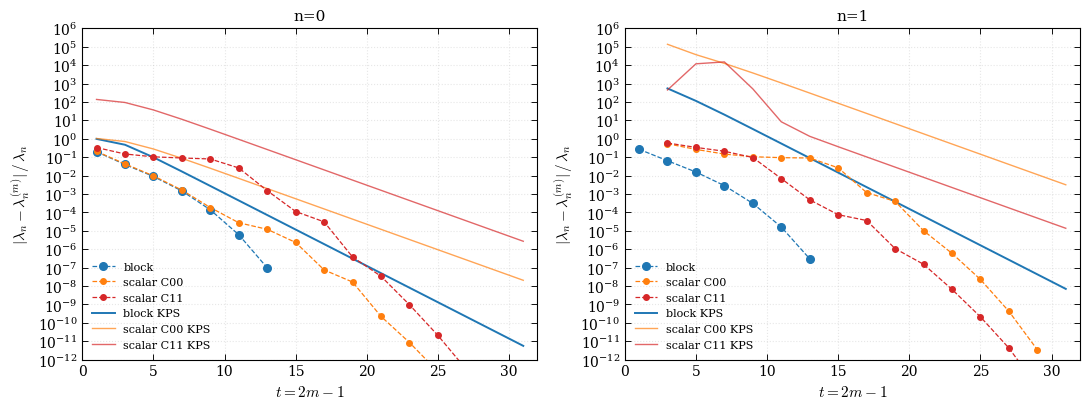

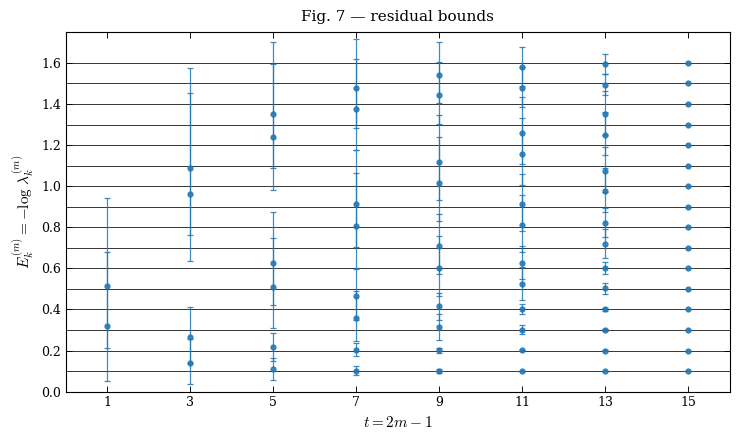

All 3 figures generated


In [5]:
#!/usr/bin/env python3
# Figures 3,6,7 of Hackett & Wagman,arXiv:2412.04444v3

import traceback
from pathlib import Path
import numpy as np
from mpmath import mp
import matplotlib.pyplot as plt
mp.dps=80
OUT=Path.cwd()

# 1. mock data (eq 72)
def build_mock(Nt=32,Ns=16):
    E,Z=[],[]
    for k in range(Ns):
        Ek=mp.mpf("0.1")*(k + 1)
        if k % 2 == 0:
            z0,z1=mp.mpf("1.0"),(mp.mpf("-0.1") if k == 0 else mp.mpf("0.1"))
        else:
            z0,z1=mp.mpf("0.1"),mp.mpf("1.0")
        Z.append((z0/mp.sqrt(2*Ek),z1/mp.sqrt(2*Ek)))
        E.append(Ek)
    C=[]
    for t in range(Nt):
        Ct=mp.matrix(2,2)
        for k in range(Ns):
            ek=mp.exp(-E[k] * t)
            for a in range(2):
                for b in range(2):
                    Ct[a,b] += Z[k][a] * Z[k][b] * ek
        C.append(Ct)
    return C,E,Z

# 2.lanczos core
def eig_values_vectors(A):
    # handle mpmath.eig returning list OR matrix
    E,ER=mp.eig(A)
    try:
        vals=[E[k,0] for k in range(E.rows)]
    except (TypeError,AttributeError):
        vals=list(E)
    if not hasattr(ER,"rows"):
        ER=mp.matrix(ER)
    return vals,ER

def factor_delta(Delta):
    r=Delta.rows
    if r == 1:
        s=mp.sqrt(Delta[0,0])
        return mp.matrix([[s]]),mp.matrix([[s]])
    vals,V=eig_values_vectors(Delta)
    Vinv=mp.inverse(V)
    S=mp.diag([mp.sqrt(vals[k]) for k in range(r)])
    return V * S,S * Vinv

def block_lanczos(C,m):
    Nt,r=len(C),C[0].rows
    if Nt<2*m:
        raise ValueError(f"block_lanczos requires Nt >= 2m; got Nt={Nt},m={m}")
    a=[None]*(m+1); b=[None]*(m+1); g=[None]*(m+1)
    A=[None]*(m+1); G=[None]*(m+1); B=[None]*(m+1)
    b1,g1=factor_delta(C[0]); b[1],g[1]=b1,g1
    ib1,ig1=mp.inverse(b1),mp.inverse(g1)
    A[1]=[ib1 * C[t] * ig1 for t in range(Nt)]
    a[1]=A[1][1]
    if m == 1:
        return dict(alpha=a,beta=b,gamma=g)

    a1=a[1]
    b2,g2=factor_delta(A[1][2] - a1*a1); b[2],g[2]=b2,g2
    ib2,ig2=mp.inverse(b2),mp.inverse(g2)
    G[2]=[ib2*(A[1][t+1] - a1*A[1][t]) for t in range(Nt-1)]
    B[2]=[(A[1][t+1] - A[1][t]*a1)*ig2 for t in range(Nt-1)]
    # corrected eq 24 A_1(t+2) leading term
    A[2]=[ib2*(A[1][t+2] + a1*A[1][t]*a1- (a1*A[1][t+1] + A[1][t+1]*a1))*ig2 for t in range(Nt-2)]
    a[2]=A[2][1]

    for j in range(2,m):
        Aj,Gj,Bj,Ajm1=A[j],G[j],B[j],A[j-1]
        aj,bj,gj=a[j],b[j],g[j]
        bn,gn=factor_delta(Aj[2] - aj*aj - gj*bj)
        b[j+1],g[j+1]=bn,gn
        ibn,ign=mp.inverse(bn),mp.inverse(gn)
        G[j+1]=[ibn*(Aj[t+1]-aj*Aj[t]-gj*Bj[t])
                  for t in range(min(len(Aj)-1,len(Bj)))]
        B[j+1]=[(Aj[t+1]-Aj[t]*aj-Gj[t]*bj)*ign
                  for t in range(min(len(Aj)-1,len(Gj)))]
        LA=min(len(Aj)-2,len(Ajm1),len(Bj)-1,len(Gj)-1)
        A[j+1]=[]
        for t in range(LA):
            term=(Aj[t+2] - (aj*Aj[t+1] + Aj[t+1]*aj)
                    + aj*Aj[t]*aj + gj*Ajm1[t]*bj
                    - (gj*Bj[t+1] + Gj[t+1]*bj)
                    + gj*Bj[t]*aj + aj*Gj[t]*bj)
            A[j+1].append(ibn*term*ign)
        a[j+1]=A[j+1][1]
    return dict(alpha=a,beta=b,gamma=g)

def assemble_T(a,b,g,m,r):
    T=mp.matrix(m*r,m*r)
    for i in range(m):
        for u in range(r):
            for v in range(r):
                T[i*r+u,i*r+v]=a[i+1][u,v]
    for i in range(m-1):
        for u in range(r):
            for v in range(r):
                T[i*r+u,(i+1)*r+v]=b[i+2][u,v]
                T[(i+1)*r+u,i*r+v]=g[i+2][u,v]
    return T

def ritz_sorted(T_m,r,beta1):
    # Eigen decompose T_m returns lam(desc),E(asc),Z[k,a] with Z_k0>0,eigenvectors Vs
    n=T_m.rows
    vals,V=eig_values_vectors(T_m)
    vals=[mp.re(v) for v in vals]
    idx =sorted(range(n),key=lambda k: -vals[k])
    lam=np.array([float(vals[k]) for k in idx])
    E=np.array([-np.log(l) if l > 0 else np.nan for l in lam])
    Vs=np.zeros((n,n))
    for j,k in enumerate(idx):
        for i in range(n):
            Vs[i,j]=float(mp.re(V[i,k]))
    Z=np.zeros((n,r))
    for k in range(n):
        for u in range(r):
            acc=mp.mpf(0)
            for v in range(r):
                acc += beta1[u,v] * Vs[v,k]
            Z[k,u]=float(acc)
        if Z[k,0] < 0:
            Z[k,:] *= -1
    return lam,E,Z,Vs

# 3. fig 3 overlap factors |Z_ka^(m)|

def run_fig3(C,E,Z_true):
    from pathlib import Path
    plt.rcParams.update({
        "font.family": "serif",
        "mathtext.fontset": "cm",
        "font.size": 10,
        "axes.linewidth": 0.8,
        "xtick.direction": "in",
        "ytick.direction": "in",
        "xtick.major.width": 0.65,
        "ytick.major.width": 0.65,
        "xtick.minor.width": 0.4,
        "ytick.minor.width": 0.4,
        "xtick.top": True,
        "ytick.right": True,
        "xtick.major.size": 4,
        "ytick.major.size": 4,
        "xtick.minor.size": 2,
        "ytick.minor.size": 2,
        "savefig.dpi": 300,
    })
    r,M=2,8
    # 2. block lanczos
    out=block_lanczos(C,M)
    T_full=assemble_T(out["alpha"],out["beta"],out["gamma"],M,r)
    b1=out["beta"][1]
    block_hist=[]
    for m in range(1,M + 1):
        T_m=mp.matrix(m * r,m * r)
        for i in range(m * r):
            for j in range(m * r):
                T_m[i,j]=T_full[i,j]
        lam,eng,Z,_=ritz_sorted(T_m,r,b1)
        block_hist.append({
            "m": m,
            "t": 2 * m - 1,
            "lambdas": lam,
            "energies": eng,
            "Z": Z,
        })
    # 3. Scalar Lanczos one independent calculation per channel
    scalar_hist={}
    for d in (0,1):
        Cd=[ mp.matrix([[C[t][d,d]]])for t in range(32)]
        od=block_lanczos(Cd,16)
        T_d=assemble_T(od["alpha"],od["beta"],od["gamma"],16,1)
        b1d=od["beta"][1]
        hist=[]
        for m in range(1,17):
            T_m=mp.matrix(m,m)
            for i in range(m):
                for j in range(m):
                    T_m[i,j]=T_d[i,j]
            lam,eng,Z,_=ritz_sorted(T_m,1,b1d)
            hist.append({"m": m,"t": 2 * m - 1,"lambdas": lam,"energies": eng,"Z": Z,})
        scalar_hist[d]=hist
    fig,axes=plt.subplots(1,2,figsize=(10.2,4.0),sharey=True,gridspec_kw={"wspace": 0.045},)
    #paper uses a restricted plotting range
    YMIN=0.04
    YMAX=4.0
    BLUE="#287DB3"
    ORANGE="#FF851B"
    RED="#E34245"
    LINE="0.42"
    MS_BLOCK_TOP=5.8
    MS_BLOCK=4.5
    MS_SCALAR_TOP=3.4
    MS_SCALAR=2.7
    for a_idx,ax in enumerate(axes):
        # true overlap levels
        for k in range(16):
            zval=float(abs(Z_true[k][a_idx]))
            if not (YMIN <= zval <= YMAX):
                continue
            is_top=k < 2
            # the negative true Z_01 overlap is shown dashed
            if k == 0 and a_idx == 1:
                linestyle="--"
            elif k % 2 == 0:
                linestyle="-"
            else:
                linestyle=":"
            ax.axhline(zval,color="black" if is_top else LINE,linewidth=0.75 if is_top else 0.45,linestyle=linestyle,zorder=0,)

        # The dotted connectors for the two leading estimates
        for k in (0,1):
            for h0,h1 in zip(block_hist[:-1],block_hist[1:]):
                z0=abs(float(h0["Z"][k,a_idx]))
                z1=abs(float(h1["Z"][k,a_idx]))
                if (YMIN <= z0 <= YMAX
                    and YMIN <= z1 <= YMAX):
                    ax.plot([h0["t"],h1["t"]],[z0,z1],color=BLUE,linestyle=":",linewidth=0.8,alpha=0.8,zorder=1,)

        scalar_color=ORANGE if a_idx == 0 else RED
        for k in (0,1):
            hist=scalar_hist[a_idx]

            for h0,h1 in zip(hist[:-1],hist[1:]):
                # scalar at iteration m has m states k=1 only exists from m=2
                if k >= h0["Z"].shape[0] or k >= h1["Z"].shape[0]:
                    continue
                z0=abs(float(h0["Z"][k,0]))
                z1=abs(float(h1["Z"][k,0]))

                if (
                    YMIN <= z0 <= YMAX
                    and YMIN <= z1 <= YMAX
                ):
                    ax.plot(
                        [h0["t"],h1["t"]],
                        [z0,z1],
                        color=scalar_color,
                        linestyle=":",
                        linewidth=0.65,
                        alpha=0.75,
                        zorder=1,
                    )

        # Block lanczos estimates
        for h in block_hist:
            for k in range(h["m"] * r):
                zv=h["Z"][k,a_idx]
                az=float(abs(zv))
                if az < 1e-14:
                    continue
                is_top=k < 2
                ms=MS_BLOCK_TOP if is_top else MS_BLOCK
                # Preserve the sign distinction with hollow mmarker
                face=BLUE if zv > 0 else "white"

                if az < YMIN:
                    # the paper uses these for the right panel estimate
                    if a_idx == 1:
                        ax.plot(
                            h["t"],YMIN,
                            marker="v",
                            markersize=ms,
                            markerfacecolor=face,
                            markeredgecolor=BLUE,
                            markeredgewidth=0.85,
                            linestyle="none",
                            clip_on=False,
                            zorder=4,
                        )
                    continue

                ax.plot(
                    h["t"],az,
                    marker="o",
                    markersize=ms,
                    markerfacecolor=face,
                    markeredgecolor=BLUE,
                    markeredgewidth=0.65,
                    linestyle="none",
                    zorder=3,
                )

        # Scalar lanczos estimates
        for h in scalar_hist[a_idx]:
            for k in range(h["m"]):
                zv=h["Z"][k,0]
                az=float(abs(zv))
                if az < YMIN or az > YMAX or az < 1e-14:
                    continue
                is_top=k < 2
                ms=MS_SCALAR_TOP if is_top else MS_SCALAR
                face=scalar_color if zv > 0 else "white"
                ax.plot(
                    h["t"],az,
                    marker="o",
                    markersize=ms,
                    markerfacecolor=face,
                    markeredgecolor=scalar_color,
                    markeredgewidth=0.55,
                    linestyle="none",
                    alpha=0.9,
                    zorder=2,
                )
        ax.set_yscale("log")
        ax.set_xlim(0,32)
        ax.set_ylim(YMIN,YMAX)
        ax.set_xticks([0,8,16,24,32])
        ax.set_xlabel(r"$t=2m - 1$",fontsize=12)
        ax.set_title(rf"$a={a_idx}$",fontsize=12,pad=7)
        ax.tick_params(
            axis="both",
            which="both",
            direction="in",
            top=True,
            right=True,
            labelsize=9,
        )
        ax.grid(False)
        for spine in ax.spines.values():
            spine.set_linewidth(0.8)
    axes[0].set_ylabel(r"$|Z_{k,a}|$",fontsize=12,labelpad=5)
    axes[1].tick_params(axis="y",labelleft=False)
    fig.subplots_adjust(
        left=0.105,
        right=0.985,
        bottom=0.17,
        top=0.89,
        wspace=0.045,
    )
    path=Path(OUT) / "fig333.png"
    path.parent.mkdir(parents=True,exist_ok=True)
    fig.savefig(
        path,
        dpi=400,
        bbox_inches="tight",
        facecolor="white",
    )
    plt.show()

    return block_hist,scalar_hist


# 4. fig 6 — relative error + KPS bound
def tan2_theta(n,r,Zlist,C0):
    # eq 86
    Z=mp.matrix(r,r)
    for i in range(r):
        for j in range(r):
            if n + i < len(Zlist) and j < len(Zlist[n+i]):
                Z[i,j]=Zlist[n+i][j]
            else:
                Z[i,j]=0
    Cinv=mp.inverse(C0)
    X=mp.matrix(r,r)
    for i in range(r):
        for j in range(r):
            s=mp.mpf(0)
            for u in range(r):
                for v in range(r):
                    s += Z[i,u] * Cinv[u,v] * Z[j,v]
            X[i,j]=s
    return float(mp.re(mp.inverse(X)[0,0])) - 1

def kps_bound(n,r,m,tan2,E,K_n):
    # eq 85
    delta=float(mp.re(E[n+r])) - float(mp.re(E[n]))
    Gamma=2.0 * np.exp(delta) - 1.0
    k=m-n-1
    if k<0:
        return np.inf
    mu=np.arccosh(Gamma)
    return K_n**2 * tan2 / np.cosh(k * mu)**2
def run_fig6(C,E,Z,block_hist,scalar_hist):
    E_np=np.array([float(mp.re(e)) for e in E])
    lam_true=np.exp(-E_np)
    # tan^2 θ_n — operator property,mindependent
    Zlist=[(complex(z[0]),complex(z[1])) for z in Z]
    tan2_block=[tan2_theta(n,2,Zlist,C[0]) for n in (0,1)]
    Zc00=[(complex(z[0]),) for z in Z]
    Zc11=[(complex(z[1]),) for z in Z]
    C00_0=mp.matrix([[C[0][0,0]]])
    C11_0=mp.matrix([[C[0][1,1]]])
    tan2_sc={
        0: [tan2_theta(n,1,Zc00,C00_0) for n in (0,1)],
        1: [tan2_theta(n,1,Zc11,C11_0) for n in (0,1)],
    }

    def K_of_n(n,engs):
        """K_n^(m)=Π_{l<n} λ_l^(m) / (λ_l^(m) − λ_n) with λ_∞=0."""
        if n == 0:
            return 1.0
        K=1.0
        for l in range(n):
            if l >= len(engs) or not np.isfinite(engs[l]):
                return np.nan
            ll=np.exp(-engs[l])# λ_l^(m)
            ln=np.exp(-E_np[n])# λ_n (true)
            if abs(ll - ln) < 1e-12:
                return np.nan
            K *= ll / (ll - ln)
        return abs(K)
    fig,axes=plt.subplots(1,2,figsize=(11,4.2))
    for n,ax in enumerate(axes):
        cases=[
            ('block',block_hist,'tab:blue',  5.5),
            ('scalar C00',scalar_hist[0], 'tab:orange',4.0),
            ('scalar C11',scalar_hist[1], 'tab:red',   4.0),
        ]
        for label,hist,col,ms in cases:
            xs,ys=[],[]
            for h in hist:
                # exists only when the m-th iteration has > n Ritz values
                if (len(h['lambdas']) > n
                        and np.isfinite(h['lambdas'][n])
                        and h['lambdas'][n] > 0):
                    err=abs(h['lambdas'][n] - lam_true[n]) / lam_true[n]
                    if 1e-15 < err < np.inf:
                        xs.append(h['t'])
                        ys.append(err)
            if xs:
                ax.plot(xs,ys,'o--',color=col,ms=ms,lw=0.9,
                        label=label,zorder=3)

        # KPS bounds (solids)
        xs_m=[2*m - 1 for m in range(1,17)]# t=1,3,......,31

        # block: actual K_n^(m) for m=1..8 then freeze K_n^(8)
        K_at_8=K_of_n(n,block_hist[7]['energies']) if n > 0 else 1.0
        yb=[]
        for m in range(1,17):
            if m - n - 1 < 0:
                yb.append(np.nan)
                continue
            if m <= 8:
                Kn=K_of_n(n,block_hist[m-1]['energies']) if n > 0 else 1.0
            else:
                Kn=K_at_8                          # ← paper's extrapolation
            yb.append(kps_bound(n,2,m,tan2_block[n],E,Kn))
        ax.plot(xs_m,yb,'-',color='tab:blue',lw=1.4,
                label='block KPS',zorder=2)

        # scalar bounds
        for d,col,name in [(0,'tab:orange','C00'),
                              (1,'tab:red',   'C11')]:
            ys=[]
            for m in range(1,17):
                if m - n - 1 < 0:
                    ys.append(np.nan)
                    continue
                hist=scalar_hist[d]
                if m - 1 >= len(hist):
                    ys.append(np.nan)
                    continue
                Kn=K_of_n(n,hist[m-1]['energies']) if n > 0 else 1.0
                ys.append(kps_bound(n,1,m,tan2_sc[d][n],E,Kn))
            ax.plot(xs_m,ys,'-',color=col,lw=1.0,alpha=0.7,
                    label=f'scalar {name} KPS',zorder=2)

        ax.set_yscale('log')
        ax.set_xlim(0,32)
        ax.set_ylim(1e-12,1e6)
        ax.set_xticks([0,5,10,15,20,25,30])
        # every decade from 10^-12 to 10^6
        ax.set_yticks([10.0**p for p in range(-12,7)])
        ax.yaxis.set_minor_locator(matplotlib.ticker.LogLocator(base=10,subs=[],numticks=100))
        ax.set_xlabel(r'$t=2m-1$',fontsize=11)
        ax.set_ylabel(r'$|\lambda_n - \lambda_n^{(m)}| \,/\,\lambda_n$',fontsize=11)
        ax.set_title(f'n={n}',fontsize=11)
        ax.legend(fontsize=8,loc='lower left',frameon=False)
        ax.grid(True,which='major',ls=':',alpha=0.3,zorder=1)
    fig.tight_layout()
    path=OUT / "fig6_reproduction.png"
    fig.savefig(path,dpi=300,bbox_inches="tight")
    plt.show()

# 5. fig 7 — residual bounds on E_k^(m)
def run_fig7(C,E):
    import matplotlib.pyplot as plt
    plt.rcParams.update({
        "font.family": "serif","mathtext.fontset": "cm","font.size": 10,
        "axes.linewidth": 0.8,"xtick.direction": "in","ytick.direction": "in",
        "xtick.major.width": 0.65,"ytick.major.width": 0.65,
        "xtick.top": True,"ytick.right": True,
    })

    r,M=2,8
    out=block_lanczos(C,M + 1)# +1 to obtain γ_{M+1}
    T_full=assemble_T(out['alpha'],out['beta'],out['gamma'],M + 1,r)
    gam=out['gamma']
    b1 =out['beta'][1]
    E_true=[float(mp.re(E[k])) for k in range(16)]
    YBOT,YTOP=0.0,1.75
    fig,ax=plt.subplots(figsize=(7.5,4.5))
    for Ek in E_true:
        ax.axhline(Ek,color='black',lw=0.55,zorder=0)
    for m in range(1,M + 1):# m=1..8 → t=1..15
        T_m=mp.matrix(m*r,m*r)
        for i in range(m*r):
            for j in range(m*r):
                T_m[i,j]=T_full[i,j]
        lam,eng,Z,Vs=ritz_sorted(T_m,r,b1)
        gn=gam[m + 1]
        for k in range(m*r):
            if lam[k] <= 0 or lam[k] > 1:
                continue
            # B_k=|omega^T [γᵀ γ] omega|,with V_k=I (Cholesky convention)
            B=mp.mpf(0)
            for u in range(r):
                for v in range(r):
                    guv=mp.mpf(0)
                    for w in range(r):
                        guv += gn[w,u] * gn[w,v]
                    B += Vs[(m-1)*r + u,k] * guv * Vs[(m-1)*r + v,k]
            B=abs(float(mp.re(B)))
            if B <= 0:
                continue
            lam_val=lam[k]
            sqrt_B =np.sqrt(B)
            lam_lo =lam_val - sqrt_B
            lam_hi =lam_val + sqrt_B
            E_c =-np.log(lam_val)
            E_lo=-np.log(lam_hi) if lam_hi > 0 else YBOT - 1.0
            E_hi=-np.log(lam_lo) if lam_lo > 0 else YTOP + 1.0   # ∞ → clip
            ax.errorbar(2*m-1,E_c,
                        yerr=[[max(E_c - E_lo,0.0)],
                              [max(E_hi - E_c,0.0)]],
                        fmt='o',color='tab:blue',ms=3.5,capsize=2.0,
                        alpha=0.85,elinewidth=0.9,capthick=0.9,zorder=2)

    ax.set_xlim(0,16)
    ax.set_ylim(YBOT,YTOP)
    ax.set_xticks([1,3,5,7,9,11,13,15])
    ax.set_xlabel(r'$t=2m-1$',fontsize=11)
    ax.set_ylabel(r'$E_k^{(m)}=-\log\,\lambda_k^{(m)}$',fontsize=11)
    ax.set_title('Fig. 7 — residual bounds',fontsize=11,pad=8)
    ax.tick_params(which='both',direction='in',top=True,right=True,labelsize=9)
    for spine in ax.spines.values():
        spine.set_linewidth(0.8)
    fig.tight_layout()
    path=OUT / "fig7_reproduction.png"
    fig.savefig(path,dpi=300,bbox_inches="tight")
    plt.show()



def main():
    C, E, Z = build_mock()
    bh, sh = None, None
    errors = []
    try:
        bh, sh = run_fig3(C, E, Z)
    except Exception as exc:
        errors.append(f"Fig 3 failed: {exc}")
    if bh is not None:
        try:
            run_fig6(C, E, Z, bh, sh)
        except Exception as exc:
            errors.append(f"Fig 6 failed: {exc}")
    else:
        errors.append("Fig 6 skipped (Fig 3 failed)")
    try:
        run_fig7(C, E)
    except Exception as exc:
        errors.append(f"Fig 7 failed: {exc}")
    if not errors:
        print("All 3 figures generated")
    else:
        print("Some tasks failed")
        for err in errors:
            print(f" - {err}")

main()